In [12]:
# mamba activate squidpy-voyagerpy_v1 
import scanpy as sc
import numpy as np
import os
import matplotlib.pyplot as plt

import pandas as pd

import alphashape as alphashape

In [13]:
import h5py
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
fn = os.path.join(pathad, "adata_nb_processed_v2.h5ad")

with h5py.File(fn, "a") as f:
    for key in [
        "uns/log1p/base",
        "uns/pca/params/mask_var",
        "uns/spatial_neighbors/params/transform",
    ]:
        if key in f:
            del f[key]

andata = sc.read_h5ad(fn)

In [14]:
andata.obs.columns

Index(['cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'sample_lab', 'mouse_id', 'Condition', 'Type', 'punch_id', 'n_genes_by_counts', 'cluster_30neig_r07', 'stlieden_ratio1p5_r13', 'annotation_v1', '0_subclusters_res_0p5'], dtype='object')

In [15]:
# Project-specific definitions (given in the task, not inferred)
color_map = {
    # Neuroblastoma — adrenergic states: blues
    "Adrenergic_Proliferating_NB": "#084594",
    "Adrenergic_Cycling_NB": "#2171B5",
    "Adrenergic_StemLike_NB": "#4292C6",
    "Adrenergic_MYCNHigh_Metabolic_NB": "#6BAED6",

    # Neuroblastoma — transitional / mesenchymal states: greens
    "Transitional_NB": "#238B45",
    "Metabolic_NB": "#41AE76",
    "Mesenchymal_NB": "#74C476",

    # Myeloid — reds
    "M2_TAM": "#B2182B",
    "MonocyteDerived_TissueResident_Macrophage": "#FF5F59",

    # Lymphoid — orange
    "CD8_Cytotoxic_TCell_PartiallyExhausted": "#F28E2B",

    # Stromal / adrenal — purples
    "Schwann_CAF": "#6A1B9A",
    "Endothelial": "#9C6BC4",
    "Adrenocortical_Steroidogenic": "#CE93D8",
}
cond_order = ['Mock', 'CAR', 'IL15', 'IL21', 'both']

# --- Validate Condition against the expected design ---
print("Condition value counts (incl. NaN):")
print(andata.obs['Condition'].value_counts(dropna=False))
present_cond = set(andata.obs['Condition'].dropna().unique())
print(f"\nCondition values not in cond_order: {present_cond - set(cond_order)}")
print(f"cond_order values missing from data: {set(cond_order) - present_cond}")

# --- Validate annotation_v1 (cell type) against color_map ---
print("\nannotation_v1 value counts (incl. NaN):")
print(andata.obs['annotation_v1'].value_counts(dropna=False))
present_ct = set(andata.obs['annotation_v1'].dropna().unique())
print(f"\nannotation_v1 categories not in color_map: {present_ct - set(color_map)}")
print(f"color_map keys missing from annotation_v1: {set(color_map) - present_ct}")

# --- Mouse <-> Condition relationship (mouse_id = individual mouse; sample_lab/punch_id are finer-grained) ---
mouse_cond = andata.obs.groupby('mouse_id')['Condition'].unique()
bad_mice = mouse_cond[mouse_cond.apply(len) > 1]
print(f"\nMice mapping to more than one Condition (should be empty):\n{bad_mice}")
print(f"\nMouse -> Condition mapping ({mouse_cond.shape[0]} mice):")
print(mouse_cond)

# --- Group sizes, smallest first, to spot unexpectedly small groups ---
print("\nCells per Condition (ascending):")
print(andata.obs['Condition'].value_counts(dropna=False).sort_values())
print("\nCells per mouse (ascending):")
print(andata.obs['mouse_id'].value_counts(dropna=False).sort_values())


Condition value counts (incl. NaN):
IL15    141324
IL21    123492
CAR     112092
Mock    104605
both     86444
Name: Condition, dtype: int64

Condition values not in cond_order: set()
cond_order values missing from data: set()

annotation_v1 value counts (incl. NaN):
Transitional_NB                              122178
Schwann_CAF                                   75029
Adrenergic_StemLike_NB                        74982
Adrenergic_Proliferating_NB                   62085
M2_TAM                                        57523
CD8_Cytotoxic_TCell_PartiallyExhausted        56964
MonocyteDerived_TissueResident_Macrophage     47465
Adrenergic_MYCNHigh_Metabolic_NB              37216
Metabolic_NB                                  24861
Mesenchymal_NB                                 7724
Adrenergic_Cycling_NB                          1663
Endothelial                                     185
Adrenocortical_Steroidogenic                     82
Name: annotation_v1, dtype: int64

annotation_v1 categor

In [16]:
def crosstab_counts_norm(obs_df, index_cols, ct_key, ct_order):
    """Raw counts and %-normalized composition of `ct_key`, grouped by `index_cols`.

    Normalizes against the true per-group total (not just the ct_order subset), so any
    cell type outside `ct_order` shows up as a normalization shortfall instead of being
    silently absorbed.
    """
    raw_full = pd.crosstab([obs_df[c] for c in index_cols], obs_df[ct_key])
    raw_full.index.names = index_cols
    denom = raw_full.sum(axis=1).replace(0, np.nan)
    raw = raw_full.reindex(columns=ct_order, fill_value=0)
    norm = (raw.div(denom, axis=0) * 100).fillna(0)
    return raw, norm

In [25]:
plt.rcParams.update({
    "font.size": 7,
    "axes.titlesize": 8,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 200,
    "savefig.dpi": 300,
})

def _draw_stack(ax, frac_df, color_map, title=None):
    """Draw one stacked-to-100% bar per row of frac_df (columns = cell types, in stacking order)."""
    x = np.arange(frac_df.shape[0])
    bottom = np.zeros(frac_df.shape[0], dtype=float)
    for ct in frac_df.columns:
        color = color_map.get(ct)
        if color is None:
            print(f"WARNING: '{ct}' not in color_map, using grey fallback")
            color = "#999999"
        ax.bar(x, frac_df[ct].values, bottom=bottom, width=0.85, color=color, edgecolor="white", linewidth=0.3, label=ct)
        bottom += frac_df[ct].values
    ax.set_ylim(0, 100)
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in frac_df.index], rotation=35, ha="right")
    ax.grid(axis="y", linewidth=0.3, alpha=0.3)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title)
    return ax


def plot_condition_composition(norm_condition, color_map, cond_order):
    """Plot 1: overall cell-type composition, one stacked bar per condition."""
    frac = norm_condition.reindex(cond_order).fillna(0)
    fig, ax = plt.subplots(figsize=(4.3, 2.6), constrained_layout=True)
    _draw_stack(ax, frac, color_map)
    ax.set_ylabel("Cell type (%)")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    return fig


def _sorted_mice(mouse_ids):
    try:
        return sorted(mouse_ids, key=lambda m: float(m))
    except (ValueError, TypeError):
        return sorted(mouse_ids, key=str)


def plot_mouse_composition(norm_mouse, color_map, cond_order):
    """Plot 2: mouse-level composition, one facet per condition (mice = bars within it)."""
    fig, axes = plt.subplots(1, len(cond_order), figsize=(2.6 * len(cond_order), 2.8), sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, cond in zip(axes, cond_order):
        if cond in norm_mouse.index.get_level_values("Condition"):
            frac = norm_mouse.loc[cond]
            frac = frac.reindex(_sorted_mice(frac.index))
        else:
            frac = pd.DataFrame(columns=norm_mouse.columns)
        _draw_stack(ax, frac, color_map, title=cond)
    axes[0].set_ylabel("Cell type (%)")

    # legend built directly from color_map so it's complete regardless of what each facet contains
    legend_handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in color_map.values()]
    fig.legend(legend_handles, list(color_map.keys()), loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig


def _fmt_id(v):
    """Render numeric-like ids (e.g. mouse_id stored as float) without a trailing '.0'."""
    try:
        return str(int(float(v)))
    except (ValueError, TypeError):
        return str(v)


def _draw_stack_grouped(ax, frac_df, color_map, tick_labels, group_labels, title=None, group_gap=0.6):
    """Like _draw_stack, but inserts an extra x-gap wherever group_labels changes (e.g. between mice)."""
    n = frac_df.shape[0]
    x = np.zeros(n)
    pos = 0.0
    for i in range(n):
        if i > 0 and group_labels[i] != group_labels[i - 1]:
            pos += group_gap
        x[i] = pos
        pos += 1.0

    bottom = np.zeros(n, dtype=float)
    for ct in frac_df.columns:
        color = color_map.get(ct)
        if color is None:
            print(f"WARNING: '{ct}' not in color_map, using grey fallback")
            color = "#999999"
        ax.bar(x, frac_df[ct].values, bottom=bottom, width=0.85, color=color, edgecolor="white", linewidth=0.3, label=ct)
        bottom += frac_df[ct].values

    ax.set_xlim(-0.7, x[-1] + 0.7 if n else 1)
    ax.set_ylim(0, 100)
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, rotation=0, fontsize=9)
    ax.grid(axis="y", linewidth=0.3, alpha=0.3)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title)
    return ax


def plot_punch_composition(norm_punch, color_map, cond_order):
    """Plot 3: punch-level composition, one facet per condition, punches grouped by mouse."""
    fig, axes = plt.subplots(1, len(cond_order), figsize=(5.2 * len(cond_order), 3.6), sharey=True, constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, cond in zip(axes, cond_order):
        if cond in norm_punch.index.get_level_values("Condition"):
            cond_df = norm_punch.loc[cond]  # MultiIndex (mouse_id, punch_id)
            mice = _sorted_mice(cond_df.index.get_level_values("mouse_id").unique())
            rows = [(m, p) for m in mice for p in _sorted_mice(cond_df.xs(m, level="mouse_id").index)]
            frac = cond_df.reindex(pd.MultiIndex.from_tuples(rows, names=["mouse_id", "punch_id"]))
            group_labels = [m for m, _ in rows]
            tick_labels = [f"M{_fmt_id(m)}\nP{_fmt_id(p)}" for m, p in rows]
        else:
            frac, group_labels, tick_labels = pd.DataFrame(columns=norm_punch.columns), [], []
        _draw_stack_grouped(ax, frac, color_map, tick_labels, group_labels, title=cond)
    axes[0].set_ylabel("Cell type (%)")
    return fig

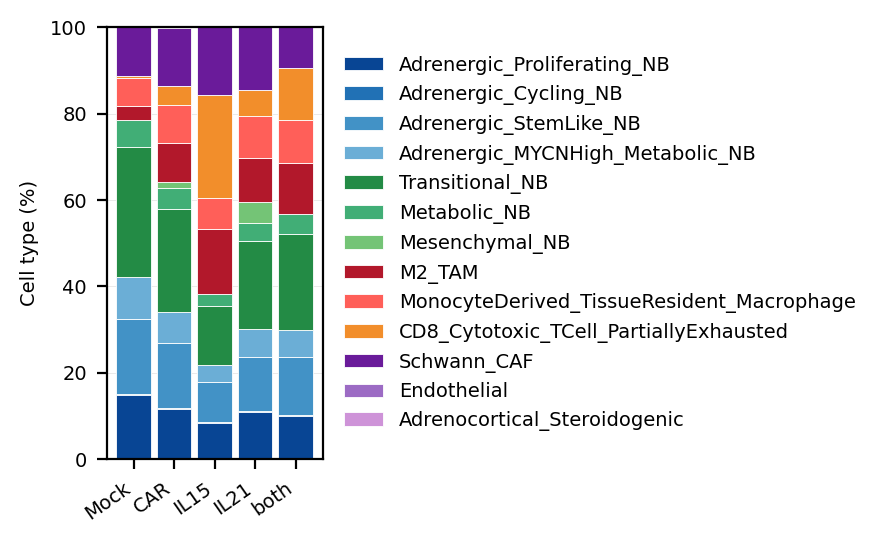

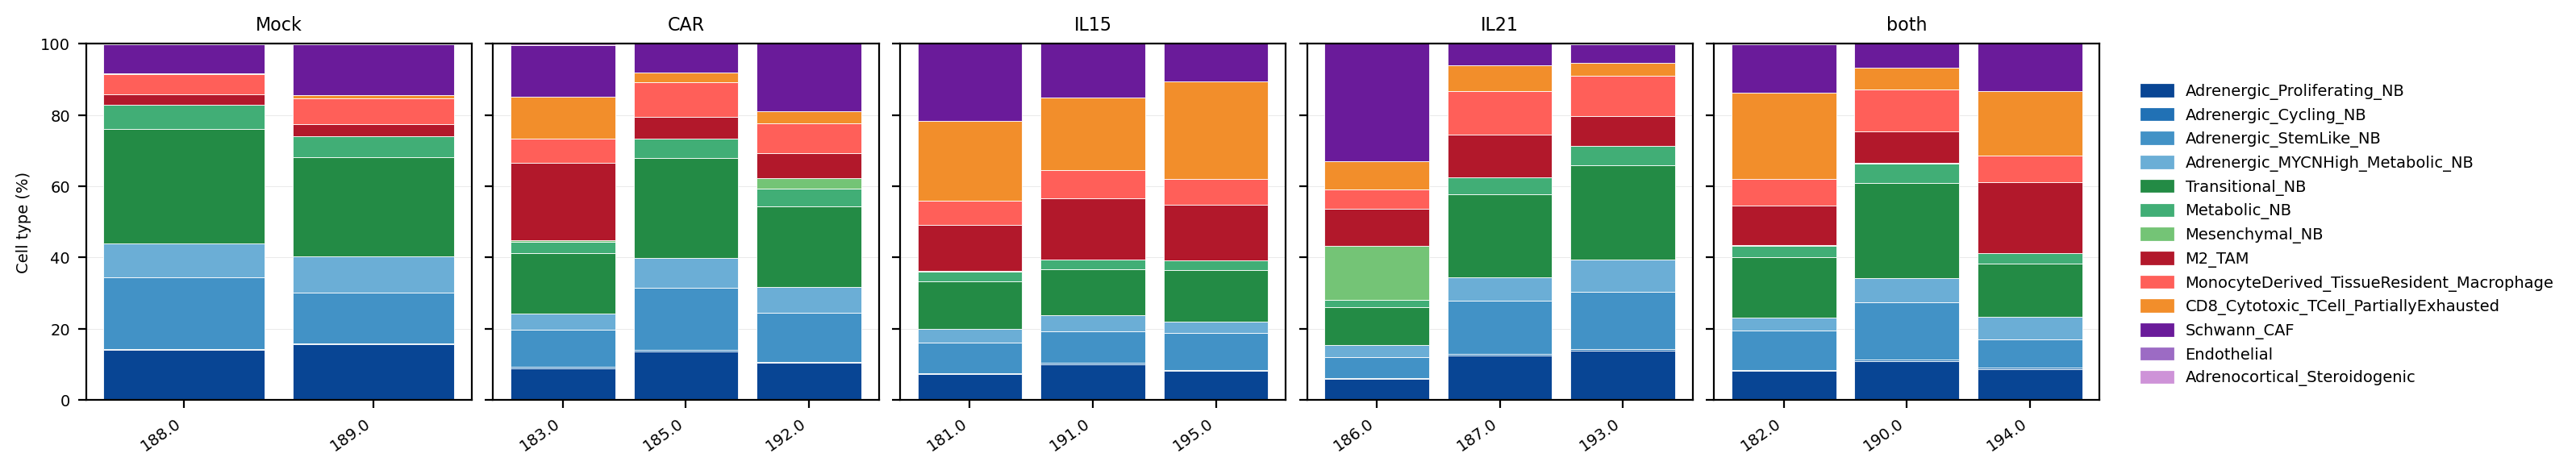


Condition composition row sums (should be ~100):
Condition
Mock    100.0
CAR     100.0
IL15    100.0
IL21    100.0
both    100.0
dtype: float64

Mouse composition row sums (should be ~100):
Condition  mouse_id
CAR        183.0       100.0
           185.0       100.0
           192.0       100.0
IL15       181.0       100.0
           191.0       100.0
           195.0       100.0
IL21       186.0       100.0
           187.0       100.0
           193.0       100.0
Mock       188.0       100.0
           189.0       100.0
both       182.0       100.0
           190.0       100.0
           194.0       100.0
dtype: float64

Mice per condition:
Condition
Mock    2
CAR     3
IL15    3
IL21    3
both    3
Name: mouse_id, dtype: int64


In [26]:
# exclude out-of-scope Condition values (e.g. leftover reference punches), flagging what's dropped
valid_mask = andata.obs['Condition'].isin(cond_order)
if (~valid_mask).sum():
    print(f"Excluding {(~valid_mask).sum()} cells with out-of-scope Condition:")
    print(andata.obs.loc[~valid_mask, ['Condition', 'mouse_id', 'punch_id']].value_counts())
obs = andata.obs.loc[valid_mask].copy()
obs['Condition'] = obs['Condition'].astype(str)

ct_order = list(color_map.keys())

# Plot 1: overall cell-type composition by condition
raw_counts_condition, norm_condition = crosstab_counts_norm(obs, ['Condition'], 'annotation_v1', ct_order)
raw_counts_condition = raw_counts_condition.reindex(cond_order).fillna(0).astype(int)
norm_condition = norm_condition.reindex(cond_order).fillna(0)
fig1 = plot_condition_composition(norm_condition, color_map, cond_order)
plt.show()

# Plot 2: mouse-level composition within each condition
raw_counts_mouse, norm_mouse = crosstab_counts_norm(obs, ['Condition', 'mouse_id'], 'annotation_v1', ct_order)
fig2 = plot_mouse_composition(norm_mouse, color_map, cond_order)
plt.show()

# --- Validation ---
print("\nCondition composition row sums (should be ~100):")
print(norm_condition.sum(axis=1))
print("\nMouse composition row sums (should be ~100):")
print(norm_mouse.sum(axis=1))
print("\nMice per condition:")
print(obs.groupby('Condition')['mouse_id'].nunique().reindex(cond_order))

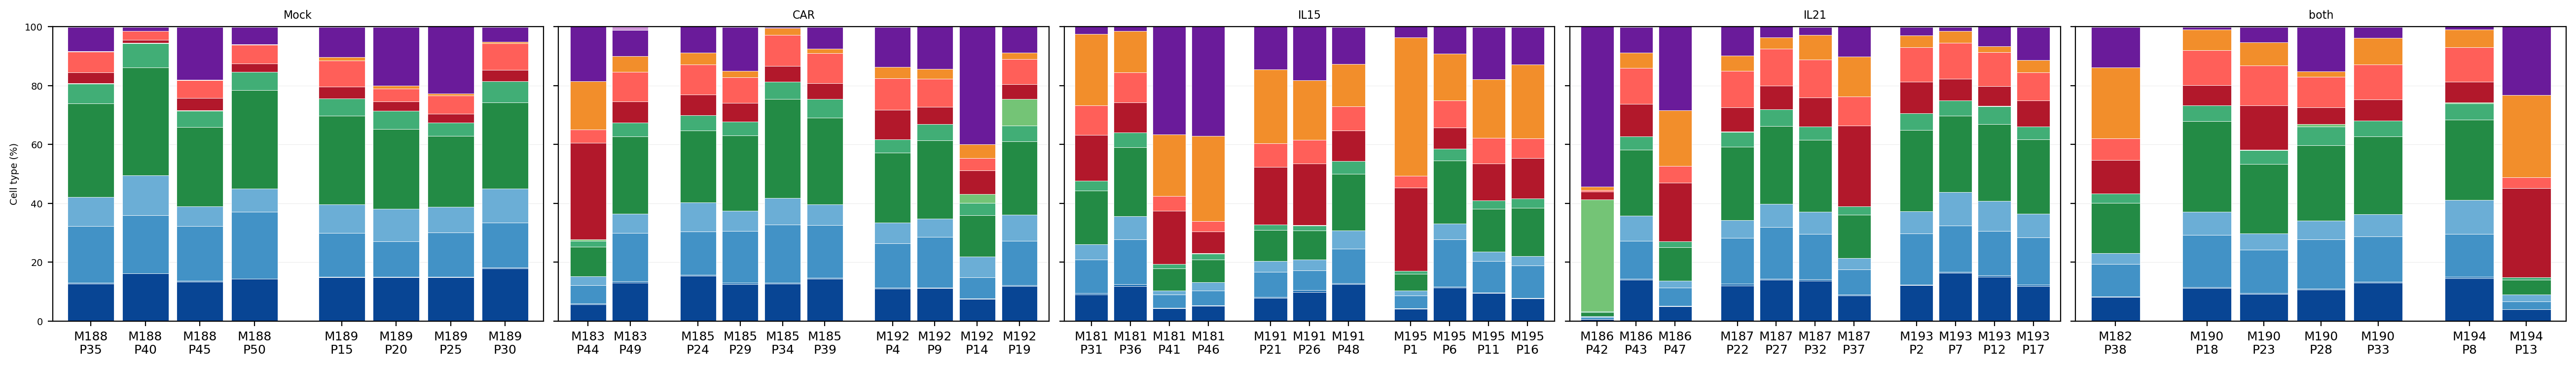


Punch composition row sums (should be ~100):
Condition  mouse_id  punch_id
CAR        183.0     44          100.0
                     49          100.0
           185.0     24          100.0
                     29          100.0
                     34          100.0
                     39          100.0
           192.0     4           100.0
                     9           100.0
                     14          100.0
                     19          100.0
IL15       181.0     31          100.0
                     36          100.0
                     41          100.0
                     46          100.0
           191.0     21          100.0
                     26          100.0
                     48          100.0
           195.0     1           100.0
                     6           100.0
                     11          100.0
                     16          100.0
IL21       186.0     42          100.0
                     43          100.0
                     47    

In [27]:
# Plot 3: punch-level composition, grouped by mouse within each condition
raw_counts_punch, norm_punch = crosstab_counts_norm(obs, ['Condition', 'mouse_id', 'punch_id'], 'annotation_v1', ct_order)
fig3 = plot_punch_composition(norm_punch, color_map, cond_order)
plt.show()

# --- Validation ---
print("\nPunch composition row sums (should be ~100):")
print(norm_punch.sum(axis=1))
print("\nPunches per mouse:")
print(obs.groupby(['Condition', 'mouse_id'], observed=True)['punch_id'].nunique())


In [20]:
# Single long table: one row per cell type x mouse x punch, with count + composition
raw_long = raw_counts_punch.rename_axis(columns="cell_type").stack().rename("n_cells")
norm_long = norm_punch.rename_axis(columns="cell_type").stack().rename("composition_pct")
comp_table = pd.concat([raw_long, norm_long], axis=1).reset_index()
comp_table["cell_type"] = pd.Categorical(comp_table["cell_type"], categories=ct_order, ordered=True)
comp_table = comp_table.sort_values(["cell_type", "Condition", "mouse_id", "punch_id"]).reset_index(drop=True)
comp_table


,Condition,mouse_id,punch_id,cell_type,n_cells,composition_pct
0,CAR,183.0,44,Adrenergic_Proliferating_NB,581,5.730913
1,CAR,183.0,49,Adrenergic_Proliferating_NB,989,13.076821
2,CAR,185.0,24,Adrenergic_Proliferating_NB,1888,15.409729
3,CAR,185.0,29,Adrenergic_Proliferating_NB,1633,12.467552
4,CAR,185.0,34,Adrenergic_Proliferating_NB,1451,12.669170
...,...,...,...,...,...,...
606,both,190.0,23,Adrenocortical_Steroidogenic,0,0.000000
607,both,190.0,28,Adrenocortical_Steroidogenic,0,0.000000
608,both,190.0,33,Adrenocortical_Steroidogenic,0,0.000000
609,both,194.0,8,Adrenocortical_Steroidogenic,0,0.000000


In [21]:
comp_table

,Condition,mouse_id,punch_id,cell_type,n_cells,composition_pct
0,CAR,183.0,44,Adrenergic_Proliferating_NB,581,5.730913
1,CAR,183.0,49,Adrenergic_Proliferating_NB,989,13.076821
2,CAR,185.0,24,Adrenergic_Proliferating_NB,1888,15.409729
3,CAR,185.0,29,Adrenergic_Proliferating_NB,1633,12.467552
4,CAR,185.0,34,Adrenergic_Proliferating_NB,1451,12.669170
...,...,...,...,...,...,...
606,both,190.0,23,Adrenocortical_Steroidogenic,0,0.000000
607,both,190.0,28,Adrenocortical_Steroidogenic,0,0.000000
608,both,190.0,33,Adrenocortical_Steroidogenic,0,0.000000
609,both,194.0,8,Adrenocortical_Steroidogenic,0,0.000000


In [22]:
comp_table.to_csv(os.path.join("tables", "NB_celltype_composition_by_punch_v1.csv"), index=False)